In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("/content/ecommerce_return_abuse_dataset.csv") # Load the dataset

In [ ]:
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])     # Display dataset information
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Number of rows: 11091
Number of columns: 35


,order_id,customer_id,age,account_age_days,customer_segment,country,platform,device_type,payment_method,product_category,...,shipping_carrier,address_change_before_delivery,refund_to_different_account,multiple_accounts_flag,customer_support_contacts,previous_dispute_count,wishlist_to_cart_time_hrs,review_left_after_return,abuse_type,abuse_label
0,ORD2024554,CUST408891,68,1473,New,US,Web Browser,iPhone,Crypto,Toys,...,OnTrac,0.0,0.0,0.0,1.0,0.0,70.5,0.0,Legitimate,0.0
1,ORD2019797,CUST898762,64,1211,Silver,FR,Tablet App,MacBook,PayPal,Books,...,FedEx,0.0,0.0,0.0,0.0,0.0,25.3,0.0,Legitimate,0.0
2,ORD2058733,CUST906263,52,1291,Bronze,US,Web Browser,iPad,Crypto,Clothing,...,FedEx,1.0,0.0,0.0,0.0,0.0,36.6,0.0,Legitimate,0.0
3,ORD2015301,CUST601672,63,1743,Bronze,CA,Web Browser,iPhone,PayPal,Home & Kitchen,...,USPS,1.0,0.0,0.0,3.0,0.0,4.4,1.0,Fraudulent Return,2.0
4,ORD2014206,CUST316429,21,2478,Gold,US,Web Browser,Windows PC,Debit Card,Clothing,...,OnTrac,0.0,0.0,0.0,1.0,1.0,40.9,0.0,Legitimate,0.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11091 entries, 0 to 11090
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   order_id                        11091 non-null  object 
 1   customer_id                     11091 non-null  object 
 2   age                             11091 non-null  int64  
 3   account_age_days                11091 non-null  int64  
 4   customer_segment                11091 non-null  object 
 5   country                         11091 non-null  object 
 6   platform                        11091 non-null  object 
 7   device_type                     11091 non-null  object 
 8   payment_method                  11091 non-null  object 
 9   product_category                11091 non-null  object 
 10  avg_order_value_usd             11091 non-null  float64
 11  refund_amount_requested_usd     11091 non-null  float64
 12  is_high_value_item              

In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
review_left_after_return,1
return_reason,1
total_orders_lifetime,1
abuse_type,1
abuse_label,1
tracking_number_valid,1
wishlist_to_cart_time_hrs,1
previous_dispute_count,1
customer_support_contacts,1
multiple_accounts_flag,1


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe

<bound method NDFrame.describe of          order_id customer_id  age  account_age_days customer_segment country  \
0      ORD2024554  CUST408891   68              1473              New      US   
1      ORD2019797  CUST898762   64              1211           Silver      FR   
2      ORD2058733  CUST906263   52              1291           Bronze      US   
3      ORD2015301  CUST601672   63              1743           Bronze      CA   
4      ORD2014206  CUST316429   21              2478             Gold      US   
...           ...         ...  ...               ...              ...     ...   
11086  ORD2008581  CUST504270   65              1438           Silver      US   
11087  ORD2002735  CUST458888   40              2381           Bronze      DE   
11088  ORD2050582  CUST893184   69               672         Platinum      FR   
11089  ORD2040535  CUST452963   20              1630           Bronze      DE   
11090  ORD2043905  CUST293352   68              1333             Gold      US   

          platform device_type payment_method product_category  ...  \
0      Web Browser      iPhone         Crypto             Toys  ...   
1       Tablet App     MacBook         PayPal            Books  ...   
2      Web Browser        iPad         Crypto         Clothing  ...   
3      Web Browser      iPhone         PayPal   Home & Kitchen  ...   
4      Web Browser  Windows PC     Debit Card         Clothing  ...   
...            ...         ...            ...              ...  ...   
11086   Mobile App     Android    Credit Card            Books  ...   
11087   Mobile App     Android         PayPal           Beauty  ...   
11088   Mobile App      iPhone         PayPal   Home & Kitchen  ...   
11089   Mobile App      iPhone    Credit Card          Grocery  ...   
11090   Tablet App     Android    Credit Card           Beauty  ...   

       shipping_carrier  address_change_before_delivery  \
0                OnTrac                             0.0   
1                 FedEx                             0.0   
2                 FedEx                             1.0   
3                  USPS                             1.0   
4                OnTrac                             0.0   
...                 ...                             ...   
11086              USPS                             0.0   
11087               DHL                             0.0   
11088              USPS                             0.0   
11089               UPS                             0.0   
11090               NaN                             NaN   

       refund_to_different_account  multiple_accounts_flag  \
0                              0.0                     0.0   
1                              0.0                     0.0   
2                              0.0                     0.0   
3                              0.0                     0.0   
4                              0.0                     0.0   
...                            ...                     ...   
11086                          0.0                     0.0   
11087                          0.0                     0.0   
11088                          0.0                     0.0   
11089                          0.0                     0.0   
11090                          NaN                     NaN   

      customer_support_contacts previous_dispute_count  \
0                           1.0                    0.0   
1                           0.0                    0.0   
2                           0.0                    0.0   
3                           3.0                    0.0   
4                           1.0                    1.0   
...                         ...                    ...   
11086                       1.0                    1.0   
11087                       1.0                    1.0   
11088                       0.0                    0.0   
11089                       1.0                    0.0   
11090                       NaN                 

In [ ]:
df["order_date"] = pd.to_datetime(
    df["order_date"], errors="coerce"
)                                               # Convert text to datetime

df["return_date"] = pd.to_datetime(
    df["return_date"], errors="coerce"
)

In [ ]:
print("Invalid order dates:",
      df["order_date"].isna().sum())

print("Invalid return dates:",
      df["return_date"].isna().sum())
invalid_dates = df[
    df["return_date"] < df["order_date"]           # Check returns dated before the order
]

print("Returns before order date:",
      len(invalid_dates))

Invalid order dates: 0
Invalid return dates: 0
Returns before order date: 0


In [ ]:
print("Earliest order:", df["order_date"].min())
print("Latest order:", df["order_date"].max())  ## View date range

Earliest order: 2022-01-01 00:00:00
Latest order: 2023-12-02 00:00:00


In [ ]:
print("RETURN REASONS")
print(df["return_reason"].value_counts())# Return reasons


RETURN REASONS
return_reason
Not As Described      1565
Changed Mind          1281
Defective/Broken      1264
Wrong Item Sent       1172
Too Large             1080
Too Small             1058
Quality Issue          805
Item Not Received      717
Found Better Price     695
Arrived Late           596
Gift Duplicate         548
Accidental Order       309
Name: count, dtype: int64


In [ ]:
print("\nABUSE TYPES")
print(df["abuse_type"].value_counts())    # Abuse types


ABUSE TYPES
abuse_type
Legitimate           7807
Policy Abuser        1328
Fraudulent Return    1106
Wardrobing            849
Name: count, dtype: int64


In [ ]:
print("\nABUSE TYPES")
print(df["abuse_type"].value_counts())           # Numeric abuse labels


ABUSE TYPES
abuse_type
Legitimate           7807
Policy Abuser        1328
Fraudulent Return    1106
Wardrobing            849
Name: count, dtype: int64


In [ ]:
print("\nREFUND BY CATEGORY")
print(
    df.groupby("product_category")[
        "refund_amount_requested_usd"
    ].agg(["count", "mean", "sum"])
    .sort_values("sum", ascending=False)         # Average requested refund by product category
    .round(2)
)


REFUND BY CATEGORY
                  count    mean        sum
product_category                          
Clothing           2322  182.78  424421.03
Electronics        1606  168.23  270178.25
Shoes              1380  183.79  253629.67
Home & Kitchen     1049  171.04  179426.04
Beauty              985  180.10  177402.61
Sports              848  177.85  150815.42
Toys                561  175.51   98462.34
Books               582  168.69   98180.01
Jewelry             490  180.78   88582.73
Grocery             423  173.04   73197.25
Furniture           426  168.68   71857.26
Tools               419  168.44   70577.29


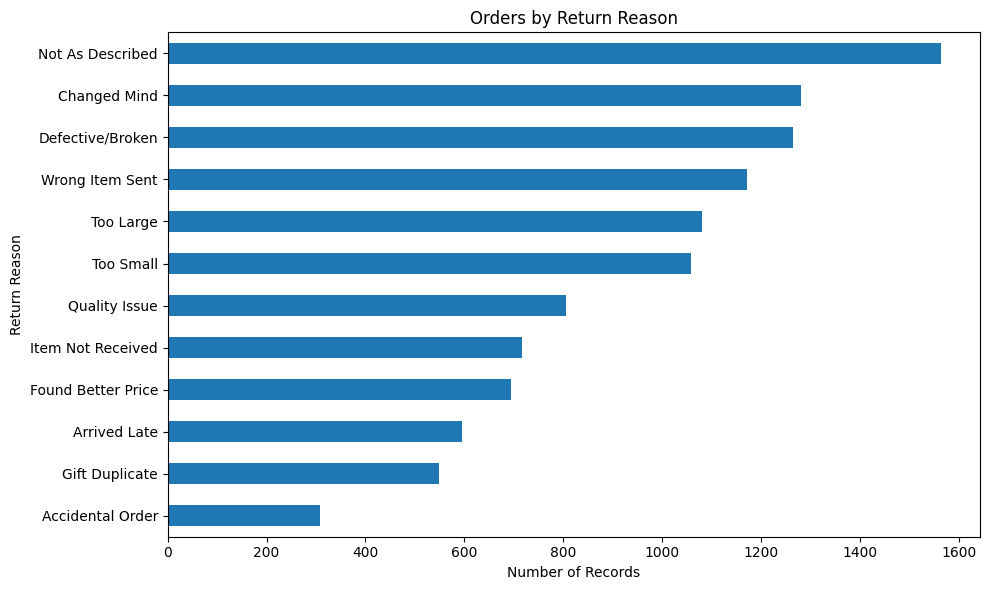

In [ ]:
reason_counts = df["return_reason"].value_counts()

plt.figure(figsize=(10, 6))
reason_counts.sort_values().plot(kind="barh")        # Count orders by return reason

plt.title("Orders by Return Reason")
plt.xlabel("Number of Records")
plt.ylabel("Return Reason")
plt.tight_layout()
plt.show()